# Meta-labeling across datasets, bar thresholds, strategies and strategy thresholds

Follow-up to `feature_engineering_meta_labeling.ipynb`, which found no usable signal for STRATEGY_432_BTC on one ETH dataset. Here the
question is **how the results change** when the bar threshold, the asset, the primary strategy and its threshold parameters change, and then
**whether any of these choices gives a positive result** that survives the number of choices tried.

"Positive" is judged on two separate criteria:

1. **Predictive meta-model**: out-of-sample log loss below the no-information prior *and* AUC above 0.5.
2. **Economics**: positive mean **net** trade return (fees included), for the unfiltered strategy and for the strategy filtered by the meta-model at the
   fixed, a-priori probability cut `p >= 0.5`. The cut is not optimised (no threshold search).

### Grid (fixed before any result, `multi_config_lib.py`)

| Dimension | Values |
|---|---|
| Asset | BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT, BNBUSDT (Binance spot) |
| Bar type | volume bars, notional bars |
| Bar threshold | about 25, 50, 100 bars per day (sizes calibrated by the pipeline) |
| Strategy × threshold parameters | RSI cross `rsi_level` ∈ {60, 70, 80}; Donchian breakout `adx_min` ∈ {15, 22, 30} × `min_break_atr` ∈ {0.25, 0.5, 1.0}; TIS momentum `streak_length` ∈ {2, 3, 4}; SuperTrend `min_signal_score` ∈ {50, 65, 80} |

30 datasets × 18 strategy configurations = **540 configurations**.

* **Costs.** Uniform for comparability: `fee_bps = 5` per fill (10 bps round trip), no slippage, tick size from each dataset's manifest. The library
  defaults differ per strategy (0–10 bps, 5 ticks of 0.1 USDT for TIS, which would be absurd on XRP).
* **Meta-model.** One fixed model for every configuration: the full eligible decision-time feature set (registry features under the point-in-time
  rules of the previous notebook, plus the strategy's non-price-level features) and a random forest with entropy, `balanced_subsample`,
  `min_weight_fraction_leaf=0.05`, 300 trees. Preprocessing (coverage ≥ 70 %, constant filter, median imputation) is fitted on training rows only.
  No feature subsets: the previous notebook found none that beat the full set.

### Protocol and the multiple-testing problem

* **Development:** trades whose label interval ends before **2025-03-01**. Out-of-fold predictions come from `PurgedKFold` (5 folds, embargo 2 %, no shuffling).
* **Holdout:** trades decided on or after 2025-03-01 (about 18 months). The meta-model is refitted on all development trades and scored once.
* The worker writes development and holdout results to separate files. **This notebook applies the selection rules (section 4) to the development
  file, freezes the selected list, and only then reads the holdout file.**

**Why this matters.** AFML §8.1: about 20 trials suffice to find a false strategy at 5 %, and here there are 540. Development scores of the best
configurations are therefore maxima over many trials. They are corrected with:

* the Benjamini–Hochberg FDR for AUC (*my choice*);
* the **Deflated Sharpe Ratio** (AFML §14.7.3) for returns, with the number of trials `N` set to the number of configurations (conservative, because
  neighbouring configurations are correlated) and also to the number of asset × strategy pairs (lenient);
* the one-time holdout check.

**Data already seen.** The holdout window overlaps the test periods of earlier notebooks (BTC 2025-26 in the v2 studies; ETH 100/day volume in
`threshold_picking.ipynb` and the previous notebook). For SOL, XRP and BNB it has not been used for strategy or model choices.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm, spearmanr

try:
    import quant_forge
except ModuleNotFoundError:
    _root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "quant_forge" / "__init__.py").exists())
    sys.path.insert(0, str(_root))
sys.path.insert(0, str(Path.cwd()))
import multi_config_lib as L

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "quant_forge" / "__init__.py").exists())
DATA_ROOT = ROOT / "data/crypto_dataset_pipeline/data/datasets"
CACHE = Path.home() / ".cache/quantforge/multi_config_meta/v1"
WORKERS = 6

# ---- selection rules, fixed before results ----
FDR_Q = 0.05            # Benjamini-Hochberg level for AUC > 0.5
DSR_MIN = 0.95          # Deflated Sharpe Ratio threshold (probability that the true SR exceeds the expected max of N null SRs)
TOP_K = 5               # additionally, the top-K development configurations per criterion go to the holdout as "best candidates"

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
if not (CACHE / "dev.parquet").exists():
    L.run_grid(DATA_ROOT, CACHE, workers=WORKERS)            # about 20 min on 16+ cores
dev = pd.read_parquet(CACHE / "dev.parquet")
dsinfo = pd.read_parquet(CACHE / "datasets.parquet")
print(f"holdout start {L.HOLDOUT_START.date()}, fee {L.FEE_BPS} bps/fill, {len(dsinfo)} datasets, {len(L.STRATEGY_GRID)} strategy configs, "
      f"{len(dev)} rows; errors: {int(dev['error'].notna().sum()) if 'error' in dev else 0}")

holdout start 2025-03-01, fee 5.0 bps/fill, 30 datasets, 18 strategy configs, 540 rows; errors: 0


## 1. Grid coverage: trades and modelled configurations

In [2]:
dev["family"] = dev["strategy"].map({"rsi_cross_above": "RSI", "donchian_breakout_continuation": "Donchian",
                                     "tis_btc_momentum_confluence": "TIS", "supertrend_regime_confluence": "SuperTrend"})
dev["param"] = dev["config"].str.split("|").str[1]
dev["key"] = dev["dataset"] + "||" + dev["config"]
if "error" in dev and dev["error"].notna().any():
    display(dev.loc[dev["error"].notna(), ["asset", "bar_type", "bars_per_day", "config", "error"]])
display(dsinfo.sort_values(["asset", "bar_type", "bars_per_day"])[["asset", "bar_type", "bars_per_day", "n_bars", "tick_size", "n_eligible_registry"]])
cov = dev.pivot_table(index=["family", "param"], columns="bars_per_day", values="dev_n", aggfunc="median")
print("median number of development trades per configuration (over assets and bar types):")
display(cov.round(0))
print(f"modelled configurations (>= {L.MIN_DEV_TRADES} development trades): {int(dev['modelled'].fillna(False).sum())} of {len(dev)}; "
      f"overlapping label intervals in any configuration: {int(dev['n_overlapping'].fillna(0).sum())}")
print(dev.groupby("family")["n_overlapping"].sum().rename("overlapping intervals").to_frame().T)

,asset,bar_type,bars_per_day,n_bars,tick_size,n_eligible_registry
23,BNBUSDT,notional,25,45629,0.00010,115
27,BNBUSDT,notional,50,91203,0.00010,115
29,BNBUSDT,notional,100,182084,0.00010,115
22,BNBUSDT,volume,25,45700,0.00010,115
25,BNBUSDT,volume,50,91155,0.00010,115
28,BNBUSDT,volume,100,182206,0.00010,115
0,BTCUSDT,notional,25,45650,0.01000,111
2,BTCUSDT,notional,50,91192,0.01000,111
6,BTCUSDT,notional,100,182329,0.01000,111
1,BTCUSDT,volume,25,45598,0.01000,111


median number of development trades per configuration (over assets and bar types):


bars_per_day                                 25      50      100
family     param                                                
Donchian   adx_min=15,min_break_atr=0.25   393.0   792.0  1570.0
           adx_min=15,min_break_atr=0.5    297.0   578.0  1159.0
           adx_min=15,min_break_atr=1       90.0   170.0   328.0
           adx_min=22,min_break_atr=0.25   269.0   534.0  1060.0
           adx_min=22,min_break_atr=0.5    197.0   392.0   796.0
           adx_min=22,min_break_atr=1       68.0   122.0   230.0
           adx_min=30,min_break_atr=0.25   144.0   290.0   558.0
           adx_min=30,min_break_atr=0.5    104.0   214.0   414.0
           adx_min=30,min_break_atr=1       40.0    68.0   136.0
RSI        rsi_level=60                   1456.0  2942.0  5890.0
           rsi_level=70                    471.0   932.0  1816.0
           rsi_level=80                     54.0    92.0   210.0
SuperTrend min_signal_score=50             132.0   270.0   574.0
           min_signal_score=65             132.0   270.0   572.0
           min_signal_score=80              25.0    48.0    99.0
TIS        streak_length=2                 267.0   576.0  1008.0
           streak_length=3                  83.0   199.0   352.0
           streak_length=4                  28.0    74.0   120.0

modelled configurations (>= 150 development trades): 364 of 540; overlapping label intervals in any configuration: 6696
family                 Donchian  RSI  SuperTrend  TIS
overlapping intervals         0    0        6696    0


Only SuperTrend shows "overlapping" label intervals. It is long/short and reverses on a flip: the new trade is decided on the bar that closes the old one,
so the closed intervals touch for a few milliseconds between exit decision and exit fill. There is no real concurrency (average uniqueness ≈ 1, AFML
ch. 4), and `PurgedKFold` purges these touching events anyway. The other strategies hold one position at a time.

## 2. How the results change — development data

### 2.1 Economics of the primary strategies (no meta-model)

Mean net return per trade in bps (10 bps round-trip cost included) and the gross equivalent, median over the configurations in each cell. A cell
summarises several configurations, so read it as a pattern, not as a test.

In [3]:
def piv(values, index, columns, agg="median", data=None):
    return (dev if data is None else data).pivot_table(index=index, columns=columns, values=values, aggfunc=agg)

print("Net mean bps per trade, by strategy configuration x asset (median over bar type and bars/day):")
display(piv("dev_mean_bps", ["family", "param"], "asset").round(1))
print("Gross mean bps per trade (before the 10 bps round trip), same layout:")
display(piv("dev_gross_mean_bps", ["family", "param"], "asset").round(1))
print("Net mean bps by strategy family x bar threshold (bars/day) x bar type:")
display(piv("dev_mean_bps", "family", ["bar_type", "bars_per_day"]).round(1))
share_pos = dev.groupby("family")[["dev_mean_bps", "dev_gross_mean_bps", "dev_t"]].apply(lambda g: pd.Series({"configs": len(g), "net mean > 0": (g["dev_mean_bps"] > 0).mean(),
                                                            "gross mean > 0": (g["dev_gross_mean_bps"] > 0).mean(),
                                                            "net t > 2": (g["dev_t"] > 2).mean()}))
print("Share of configurations with positive development returns:")
display(share_pos.round(3))

Net mean bps per trade, by strategy configuration x asset (median over bar type and bars/day):


asset                                     BNBUSDT  BTCUSDT  ETHUSDT  SOLUSDT  XRPUSDT
family     param                                                                     
Donchian   adx_min=15,min_break_atr=0.25     -3.9     -7.8    -10.7     -3.1     -3.7
           adx_min=15,min_break_atr=0.5      -1.9     -5.9     -5.6      2.4     -3.2
           adx_min=15,min_break_atr=1         9.1     -2.9      2.8      2.0    -11.9
           adx_min=22,min_break_atr=0.25     -2.5     -6.3    -10.2     -9.4     -1.9
           adx_min=22,min_break_atr=0.5       2.7      2.6     -2.9      0.3     -4.3
           adx_min=22,min_break_atr=1        13.7      5.3     -2.9      9.9    -15.4
           adx_min=30,min_break_atr=0.25      2.4     -4.1    -18.5    -17.1    -12.4
           adx_min=30,min_break_atr=0.5       7.9      2.1    -13.5     -8.1      0.4
           adx_min=30,min_break_atr=1        15.0      3.0    -10.0      6.0    -21.2
RSI        rsi_level=60                      -6.3     -8.2     -8.0    -10.5     -7.6
           rsi_level=70                      -7.1     -4.9     -9.2    -17.3     -3.4
           rsi_level=80                     -11.1     -9.8     -8.0    -38.0     -5.7
SuperTrend min_signal_score=50              -14.6    -17.7    -28.0    -31.2    -47.4
           min_signal_score=65              -12.1    -18.4    -32.2    -30.5    -49.8
           min_signal_score=80              -19.9    -36.6   -114.4   -171.2    -52.5
TIS        streak_length=2                  -13.7     -4.5    -13.8     -0.8    -11.9
           streak_length=3                  -17.0     -3.7     -8.8     11.9      0.2
           streak_length=4                  -11.9      5.3    -55.6     -5.8     23.1

Gross mean bps per trade (before the 10 bps round trip), same layout:


asset                                     BNBUSDT  BTCUSDT  ETHUSDT  SOLUSDT  XRPUSDT
family     param                                                                     
Donchian   adx_min=15,min_break_atr=0.25      6.1      2.2     -0.7      6.9      6.3
           adx_min=15,min_break_atr=0.5       8.1      4.1      4.4     12.4      6.8
           adx_min=15,min_break_atr=1        19.1      7.1     12.8     12.0     -1.9
           adx_min=22,min_break_atr=0.25      7.5      3.7     -0.2      0.6      8.1
           adx_min=22,min_break_atr=0.5      12.7     12.6      7.1     10.4      5.7
           adx_min=22,min_break_atr=1        23.7     15.3      7.1     19.9     -5.4
           adx_min=30,min_break_atr=0.25     12.4      5.9     -8.5     -7.2     -2.4
           adx_min=30,min_break_atr=0.5      17.9     12.1     -3.5      1.9     10.4
           adx_min=30,min_break_atr=1        25.0     13.0      0.0     16.0    -11.2
RSI        rsi_level=60                       3.7      1.8      2.0     -0.5      2.4
           rsi_level=70                       2.9      5.1      0.8     -7.3      6.6
           rsi_level=80                      -1.1      0.2      2.0    -28.0      4.3
SuperTrend min_signal_score=50               -4.6     -7.7    -18.0    -21.2    -37.3
           min_signal_score=65               -2.1     -8.4    -22.2    -20.5    -39.8
           min_signal_score=80              -10.0    -26.6   -104.4   -161.1    -42.5
TIS        streak_length=2                   -3.7      5.6     -3.8      9.2     -1.9
           streak_length=3                   -7.0      6.3      1.2     21.9     10.2
           streak_length=4                   -1.9     15.3    -45.7      4.2     33.1

Net mean bps by strategy family x bar threshold (bars/day) x bar type:


bar_type     notional             volume           
bars_per_day      25    50    100    25   50    100
family                                             
Donchian          0.5  -4.4  -5.3    4.5 -5.4  -3.9
RSI              -7.5  -7.1  -8.3   -6.1 -7.8  -8.7
SuperTrend      -85.7 -24.0 -38.9  -24.9  8.6  -6.5
TIS              -2.8  -8.2  -5.2  -13.6 -5.1 -10.5

Share of configurations with positive development returns:


,configs,net mean > 0,gross mean > 0,net t > 2
family,,,,
Donchian,270.0,0.411,0.741,0.019
RSI,90.0,0.044,0.689,0.000
SuperTrend,90.0,0.267,0.333,0.000
TIS,90.0,0.322,0.567,0.000


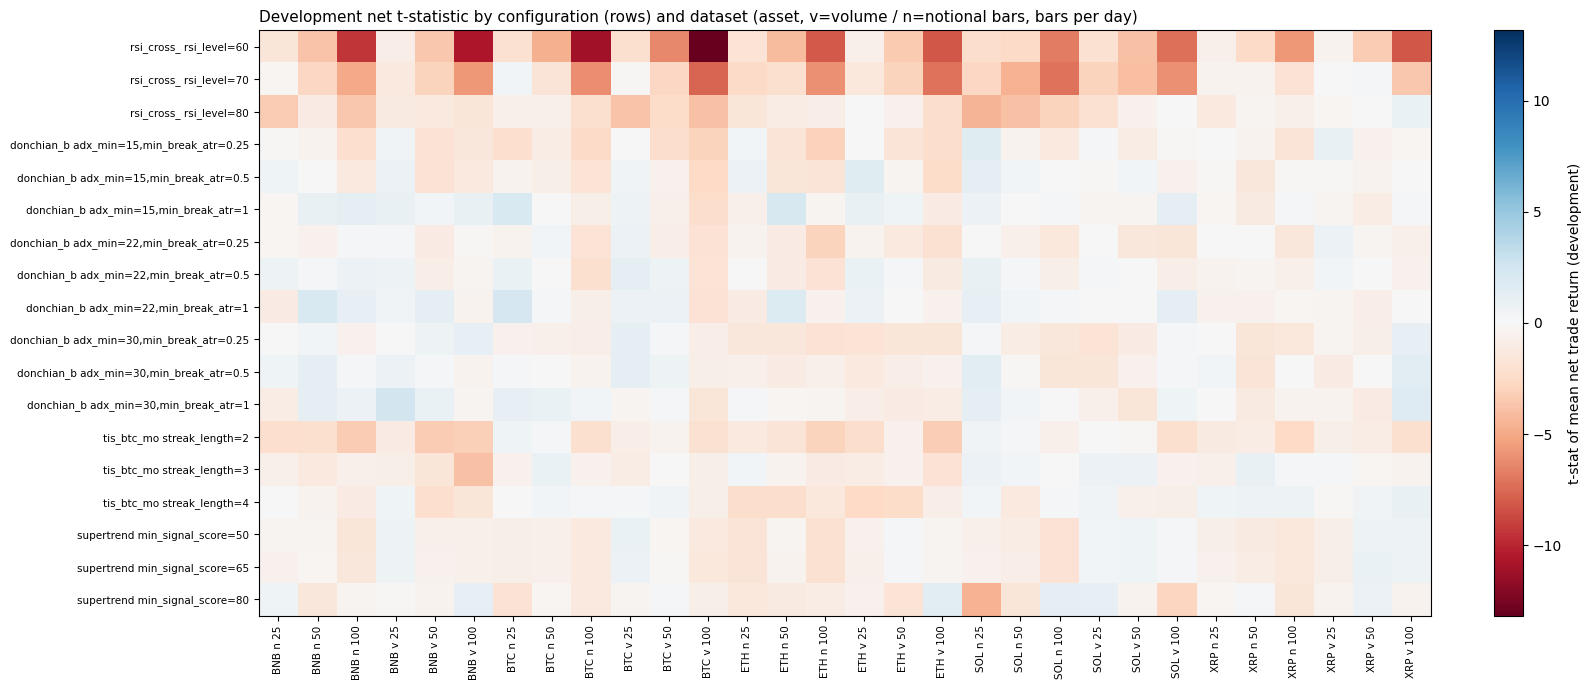

In [4]:
# heat map: development net t-statistic for every configuration (rows) x dataset (columns)
hm = dev.pivot_table(index="config", columns=["asset", "bar_type", "bars_per_day"], values="dev_t")
hm = hm.loc[[L.strategy_label(s, p) for s, p in L.STRATEGY_GRID]]
fig, ax = plt.subplots(figsize=(16, 7))
lim = np.nanmax(np.abs(hm.to_numpy()))
im = ax.imshow(hm.to_numpy(), cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(hm))); ax.set_yticklabels([c.split("|")[0][:10] + " " + c.split("|")[1] for c in hm.index], fontsize=7.5)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([f"{a[:3]} {b[0]} {n}" for a, b, n in hm.columns], rotation=90, fontsize=7.5)
cb = fig.colorbar(im, ax=ax, fraction=0.025); cb.set_label("t-stat of mean net trade return (development)")
ax.set_title("Development net t-statistic by configuration (rows) and dataset (asset, v=volume / n=notional bars, bars per day)", loc="left", fontsize=11)
fig.tight_layout(); plt.show()

### 2.2 Predictability of the meta-label

`Δ log loss = OOF log loss − prior log loss` (negative = the model beats the training share). The AUC p-value is one-sided, using the Mann–Whitney null
standard error `sqrt((n0 + n1 + 1) / (12 n0 n1))`.

In [5]:
m = dev[dev["modelled"].fillna(False)].copy()
n1 = (m["base_rate"] * m["n_dev_modelled"]).round(); n0 = m["n_dev_modelled"] - n1
m["auc_z"] = (m["oof_auc"] - 0.5) / np.sqrt((n0 + n1 + 1) / (12 * n0 * n1))
m["auc_p"] = 1 - norm.cdf(m["auc_z"])
_o = m["auc_p"].sort_values(ascending=False)                        # Benjamini-Hochberg adjusted p-values
m["auc_q_bh"] = (_o * len(_o) / np.arange(len(_o), 0, -1)).cummin().clip(upper=1).reindex(m.index)
print("Median OOF Δ log loss (x1000) by strategy configuration x asset:")
display((1000 * piv("oof_dlogloss_vs_prior", ["family", "param"], "asset", data=m)).round(1))
print("Median OOF AUC by strategy configuration x asset:")
display(piv("oof_auc", ["family", "param"], "asset", data=m).round(3))
print("Median OOF AUC by strategy family x bar type x bars/day:")
display(piv("oof_auc", "family", ["bar_type", "bars_per_day"], data=m).round(3))
summ = pd.Series({
    "modelled configurations": len(m),
    "Δ log loss < 0 (beats prior)": int((m["oof_dlogloss_vs_prior"] < 0).sum()),
    "AUC > 0.5": int((m["oof_auc"] > 0.5).sum()),
    "nominal p(AUC>0.5) < 0.05": int((m["auc_p"] < 0.05).sum()),
    "expected under the null (5 %)": round(0.05 * len(m), 1),
    f"BH q < {FDR_Q}": int((m["auc_q_bh"] < FDR_Q).sum()),
    "Δ log loss < 0 AND BH q < 0.05": int(((m["oof_dlogloss_vs_prior"] < 0) & (m["auc_q_bh"] < FDR_Q)).sum()),
    "median AUC": round(m["oof_auc"].median(), 4),
})
display(summ.to_frame("development"))

Median OOF Δ log loss (x1000) by strategy configuration x asset:


asset                                     BNBUSDT  BTCUSDT  ETHUSDT  SOLUSDT  XRPUSDT
family     param                                                                     
Donchian   adx_min=15,min_break_atr=0.25      5.8      4.6      6.6      2.0      6.8
           adx_min=15,min_break_atr=0.5       3.1      2.2      9.0      2.8      3.7
           adx_min=15,min_break_atr=1         4.3     11.4      4.6     12.5     16.8
           adx_min=22,min_break_atr=0.25      3.5      6.7     11.5     13.1      2.8
           adx_min=22,min_break_atr=0.5      10.7     14.7      4.7      7.7      8.8
           adx_min=22,min_break_atr=1        20.8     11.8     24.1    -14.3      8.0
           adx_min=30,min_break_atr=0.25      4.4     10.0     11.9      6.8     12.3
           adx_min=30,min_break_atr=0.5      20.5      3.4     16.2      1.0      8.9
           adx_min=30,min_break_atr=1         NaN     25.9      NaN      NaN     15.9
RSI        rsi_level=60                     107.0    137.0     99.2     96.5    101.7
           rsi_level=70                      55.5     52.3     51.6     70.6     58.6
           rsi_level=80                      28.6     32.7     30.0     38.6     14.8
SuperTrend min_signal_score=50               34.0     24.0     20.4     24.4     30.6
           min_signal_score=65               36.6     25.1     20.1     26.9     31.5
TIS        streak_length=2                   89.9    107.2     52.7     75.6     82.3
           streak_length=3                   41.0     29.9     44.0     58.3     54.5
           streak_length=4                    NaN     22.6      NaN     60.7      NaN

Median OOF AUC by strategy configuration x asset:


asset                                     BNBUSDT  BTCUSDT  ETHUSDT  SOLUSDT  XRPUSDT
family     param                                                                     
Donchian   adx_min=15,min_break_atr=0.25    0.492    0.530    0.504    0.524    0.505
           adx_min=15,min_break_atr=0.5     0.519    0.522    0.504    0.521    0.504
           adx_min=15,min_break_atr=1       0.530    0.479    0.502    0.501    0.481
           adx_min=22,min_break_atr=0.25    0.508    0.515    0.484    0.502    0.518
           adx_min=22,min_break_atr=0.5     0.506    0.500    0.521    0.509    0.481
           adx_min=22,min_break_atr=1       0.477    0.504    0.453    0.589    0.533
           adx_min=30,min_break_atr=0.25    0.509    0.504    0.487    0.508    0.491
           adx_min=30,min_break_atr=0.5     0.469    0.530    0.471    0.533    0.510
           adx_min=30,min_break_atr=1         NaN    0.481      NaN      NaN    0.499
RSI        rsi_level=60                     0.541    0.559    0.506    0.522    0.545
           rsi_level=70                     0.494    0.538    0.525    0.494    0.522
           rsi_level=80                     0.487    0.502    0.459    0.414    0.507
SuperTrend min_signal_score=50              0.524    0.500    0.526    0.540    0.516
           min_signal_score=65              0.511    0.517    0.528    0.537    0.490
TIS        streak_length=2                  0.530    0.540    0.555    0.505    0.500
           streak_length=3                  0.535    0.582    0.529    0.487    0.484
           streak_length=4                    NaN    0.507      NaN    0.439      NaN

Median OOF AUC by strategy family x bar type x bars/day:


bar_type     notional               volume              
bars_per_day      25     50     100    25     50     100
family                                                  
Donchian        0.503  0.499  0.501  0.512  0.511  0.504
RSI             0.516  0.539  0.518  0.517  0.497  0.524
SuperTrend        NaN  0.499  0.518  0.503  0.522  0.510
TIS             0.514  0.542  0.513  0.526  0.523  0.524

,development
modelled configurations,364.0000
Δ log loss < 0 (beats prior),39.0000
AUC > 0.5,227.0000
nominal p(AUC>0.5) < 0.05,75.0000
expected under the null (5 %),18.2000
BH q < 0.05,36.0000
Δ log loss < 0 AND BH q < 0.05,8.0000
median AUC,0.5117


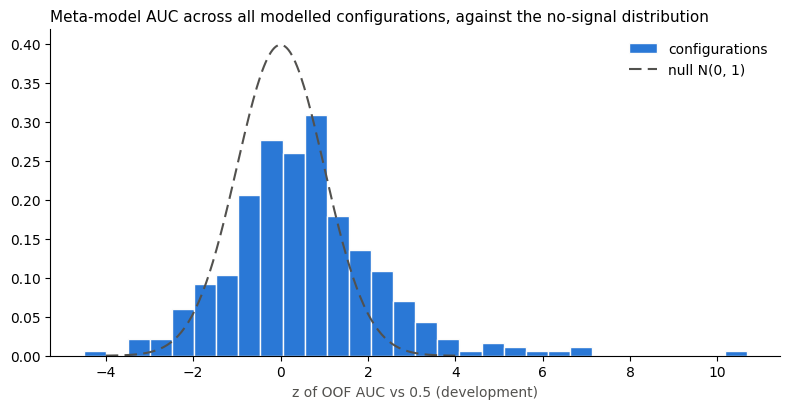

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(m["auc_z"], bins=30, color="#2a78d6", edgecolor="#fcfcfb", density=True, label="configurations")
xs = np.linspace(-4, 4, 200)
ax.plot(xs, norm.pdf(xs), color="#52514e", lw=1.5, ls=(0, (6, 3)), label="null N(0, 1)")
ax.set_xlabel("z of OOF AUC vs 0.5 (development)", color="#52514e")
ax.set_title("Meta-model AUC across all modelled configurations, against the no-signal distribution", loc="left", fontsize=11)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False); fig.tight_layout(); plt.show()

### 2.3 Deflated Sharpe Ratio of development returns (AFML §14.7.3)

Per-trade Sharpe ratio `SR = mean / sd` of net returns, with `T` trades, skewness `γ3` and kurtosis `γ4`.

* **PSR:** `Φ((SR − SR*) √(T−1) / √(1 − γ3·SR + (γ4−1)/4·SR²))`.
* **Expected maximum of `N` null Sharpe ratios:** `SR* = √V[SR_n] · ((1−γ) Φ⁻¹(1 − 1/N) + γ Φ⁻¹(1 − 1/(N e)))`, with `γ` the Euler–Mascheroni
  constant and `V[SR_n]` the variance of the Sharpe ratios across the trials.
* The DSR is the PSR evaluated at `SR*`. It is computed for the unfiltered strategy (all configurations with ≥ 30 development trades) and for the
  meta-filtered strategy (modelled configurations, accepted trades only).
* `N` = number of configurations (conservative) and `N` = 20 asset × strategy-family pairs (lenient: treats parameter and bar variants as one trial).

In [7]:
EULER = 0.5772156649

def psr(sr, sr_star, T, skew, kurt):
    den = np.sqrt(np.maximum(1 - skew * sr + (kurt - 1) / 4 * sr ** 2, 1e-12))
    return norm.cdf((sr - sr_star) * np.sqrt(T - 1) / den)

def dsr_table(frame, prefix, n_trials):
    f = frame[frame[f"{prefix}n"] >= 30].copy()
    v = f[f"{prefix}sr"].var(ddof=1)
    sr_star = np.sqrt(v) * ((1 - EULER) * norm.ppf(1 - 1 / n_trials) + EULER * norm.ppf(1 - 1 / (n_trials * np.e)))
    f["psr0"] = psr(f[f"{prefix}sr"], 0.0, f[f"{prefix}n"], f[f"{prefix}skew"], f[f"{prefix}kurt"])
    f["dsr"] = psr(f[f"{prefix}sr"], sr_star, f[f"{prefix}n"], f[f"{prefix}skew"], f[f"{prefix}kurt"])
    return f, sr_star

N_PAIRS = dev[["asset", "family"]].drop_duplicates().shape[0]
unf, sr_star_unf = dsr_table(dev, "dev_", n_trials=int((dev["dev_n"] >= 30).sum()))
unf_len, sr_star_unf_len = dsr_table(dev, "dev_", n_trials=N_PAIRS)
flt, sr_star_flt = dsr_table(m, "dev_filt_", n_trials=int((m["dev_filt_n"] >= 30).sum()))
flt_len, sr_star_flt_len = dsr_table(m, "dev_filt_", n_trials=N_PAIRS)
print(f"unfiltered: {len(unf)} trials, SR* = {sr_star_unf:.4f} per trade (lenient N={N_PAIRS}: {sr_star_unf_len:.4f}); "
      f"PSR(0) > 0.95: {int((unf['psr0'] > 0.95).sum())}; DSR > {DSR_MIN}: {int((unf['dsr'] > DSR_MIN).sum())} "
      f"(lenient: {int((unf_len['dsr'] > DSR_MIN).sum())})")
print(f"filtered  : {len(flt)} trials, SR* = {sr_star_flt:.4f} (lenient {sr_star_flt_len:.4f}); "
      f"PSR(0) > 0.95: {int((flt['psr0'] > 0.95).sum())}; DSR > {DSR_MIN}: {int((flt['dsr'] > DSR_MIN).sum())} "
      f"(lenient: {int((flt_len['dsr'] > DSR_MIN).sum())})")
cols = ["asset", "bar_type", "bars_per_day", "config", "dev_n", "dev_mean_bps", "dev_t", "dev_sr", "psr0", "dsr"]
print("Top 10 unfiltered configurations by development t-stat:")
display(unf.sort_values("dev_t", ascending=False)[cols].head(10).round(4))

unfiltered: 523 trials, SR* = 0.2713 per trade (lenient N=20: 0.1682); PSR(0) > 0.95: 8; DSR > 0.95: 0 (lenient: 0)
filtered  : 316 trials, SR* = 0.3161 (lenient 0.2063); PSR(0) > 0.95: 10; DSR > 0.95: 0 (lenient: 0)
Top 10 unfiltered configurations by development t-stat:


,asset,bar_type,bars_per_day,config,dev_n,dev_mean_bps,dev_t,dev_sr,psr0,dsr
407,BNBUSDT,volume,25,"donchian_breakout_continuation|adx_min=30,min_...",30,96.0516,2.4265,0.4430,0.9939,0.8344
8,BTCUSDT,notional,25,"donchian_breakout_continuation|adx_min=22,min_...",84,61.9833,2.2263,0.2429,0.9828,0.4023
167,ETHUSDT,notional,50,"donchian_breakout_continuation|adx_min=15,min_...",139,37.1148,2.0619,0.1749,0.9823,0.1229
494,BNBUSDT,notional,50,"donchian_breakout_continuation|adx_min=22,min_...",95,46.9198,2.0176,0.2070,0.9839,0.2530
5,BTCUSDT,notional,25,"donchian_breakout_continuation|adx_min=15,min_...",107,47.9260,2.0160,0.1949,0.9761,0.2189
170,ETHUSDT,notional,50,"donchian_breakout_continuation|adx_min=22,min_...",98,37.5038,1.7624,0.1780,0.9631,0.1745
443,XRPUSDT,volume,100,"donchian_breakout_continuation|adx_min=30,min_...",168,27.6077,1.6818,0.1298,0.9610,0.0272
219,SOLUSDT,notional,25,"donchian_breakout_continuation|adx_min=15,min_...",368,33.7891,1.6239,0.0846,0.9569,0.0001
76,ETHUSDT,volume,25,"donchian_breakout_continuation|adx_min=15,min_...",274,28.7503,1.6076,0.0971,0.9452,0.0021
226,SOLUSDT,notional,25,"donchian_breakout_continuation|adx_min=30,min_...",67,70.0316,1.5341,0.1874,0.9217,0.2631


## 3. Does the meta-filter change the economics on development data?

The filter is the fixed cut `p >= 0.5` on OOF probabilities. Compared on the same configurations, the question is whether the accepted trades have a
higher mean net return than all trades.

In [8]:
m["filt_minus_all_bps"] = m["dev_filt_mean_bps"] - m["dev_mean_bps"]
m["accept_rate"] = m["dev_filt_n"] / m["dev_n"]
print("Median over configurations, by strategy family:")
display(m.groupby("family")[["dev_mean_bps", "dev_filt_mean_bps", "filt_minus_all_bps", "accept_rate"]].median().round(3))
print(f"configurations where the filter raises the mean net return: {int((m['filt_minus_all_bps'] > 0).sum())} of {int(m['filt_minus_all_bps'].notna().sum())}")
print(f"Spearman(OOF AUC, filter improvement in bps) = {spearmanr(m['oof_auc'], m['filt_minus_all_bps'], nan_policy='omit')[0]:.3f}")

Median over configurations, by strategy family:


,dev_mean_bps,dev_filt_mean_bps,filt_minus_all_bps,accept_rate
family,,,,
Donchian,-3.919,-0.844,1.794,0.467
RSI,-7.712,-5.419,2.692,0.233
SuperTrend,-13.557,21.580,30.058,0.195
TIS,-6.782,-18.789,-12.032,0.061


configurations where the filter raises the mean net return: 210 of 364
Spearman(OOF AUC, filter improvement in bps) = 0.460


## 4. Selection on development data — frozen before the holdout is read

| Criterion | Rule (fixed in advance) | Plus |
|---|---|---|
| **P** predictive meta-model | Δ log loss < 0 **and** BH-adjusted p(AUC > 0.5) < 0.05 | top-5 by Δ log loss |
| **E1** unfiltered economics | DSR > 0.95 with conservative `N` | top-5 by development t |
| **E2** meta-filtered economics (`p >= 0.5`) | DSR > 0.95 with conservative `N` | top-5 by filtered development t |

The "top-5" candidates are not claimed to be significant. They test whether the development ranking carries any information into the holdout.

In [9]:
sel = {
    "P: pass (Δll<0 & BH q<0.05)": m.loc[(m["oof_dlogloss_vs_prior"] < 0) & (m["auc_q_bh"] < FDR_Q), "key"].tolist(),
    "P: top-5 by Δ log loss": m.sort_values("oof_dlogloss_vs_prior")["key"].head(TOP_K).tolist(),
    "E1: pass (DSR>0.95)": unf.loc[unf["dsr"] > DSR_MIN, "key"].tolist(),
    "E1: top-5 by dev t": unf.sort_values("dev_t", ascending=False)["key"].head(TOP_K).tolist(),
    "E2: pass (DSR>0.95)": flt.loc[flt["dsr"] > DSR_MIN, "key"].tolist(),
    "E2: top-5 by filtered dev t": flt.sort_values("dev_filt_t", ascending=False)["key"].head(TOP_K).tolist(),
}
FROZEN = json.dumps(sel, sort_keys=True)
print("selection fingerprint (sha256):", hashlib.sha256(FROZEN.encode()).hexdigest()[:16])
for k, v in sel.items():
    print(f"\n{k}: {len(v)}")
    for key in v:
        print("   ", key.split("||")[1], "|", dev.set_index("key").at[key, "asset"], dev.set_index("key").at[key, "bar_type"],
              dev.set_index("key").at[key, "bars_per_day"])

selection fingerprint (sha256): 0e0419f1067c9e83

P: pass (Δll<0 & BH q<0.05): 8
    donchian_breakout_continuation|adx_min=15,min_break_atr=0.5 | BTCUSDT notional 100
    donchian_breakout_continuation|adx_min=15,min_break_atr=0.25 | ETHUSDT notional 50
    donchian_breakout_continuation|adx_min=22,min_break_atr=0.5 | ETHUSDT notional 50
    donchian_breakout_continuation|adx_min=15,min_break_atr=0.5 | SOLUSDT notional 100
    donchian_breakout_continuation|adx_min=22,min_break_atr=1 | SOLUSDT notional 100
    donchian_breakout_continuation|adx_min=22,min_break_atr=0.25 | XRPUSDT notional 50
    donchian_breakout_continuation|adx_min=15,min_break_atr=0.5 | BNBUSDT volume 100
    donchian_breakout_continuation|adx_min=15,min_break_atr=0.5 | BNBUSDT notional 100

P: top-5 by Δ log loss: 5
    donchian_breakout_continuation|adx_min=22,min_break_atr=1 | SOLUSDT notional 100
    donchian_breakout_continuation|adx_min=15,min_break_atr=1 | SOLUSDT notional 100
    donchian_breakout_continuat

## 5. Holdout (2025-03-01 → 2026-08-31) — read only now

### 5.1 The selected configurations

In [10]:
hold = pd.read_parquet(CACHE / "holdout.parquet")
hold["key"] = hold["dataset"] + "||" + hold["config"]
H, Dv = hold.set_index("key"), dev.set_index("key")

def holdout_rows(keys):
    rows = []
    for k in keys:
        h, d = H.loc[k], Dv.loc[k]
        n1 = h.get("hold_base_rate", np.nan) * h.get("hold_n", np.nan)
        n0 = h.get("hold_n", np.nan) - n1
        auc_p = 1 - norm.cdf((h.get("hold_auc", np.nan) - 0.5) / np.sqrt((n0 + n1 + 1) / (12 * n0 * n1))) if bool(h.get("modelled") == True) else np.nan
        rows.append({"config": k.split("||")[1], "asset": d["asset"], "bar": f"{d['bar_type']} {d['bars_per_day']}",
                     "dev_n": d["dev_n"], "dev_mean_bps": d["dev_mean_bps"], "dev_auc": d.get("oof_auc"), "dev_dll": d.get("oof_dlogloss_vs_prior"),
                     "hold_n": h.get("hold_n"), "hold_mean_bps": h.get("hold_mean_bps"), "hold_t": h.get("hold_t"),
                     "hold_auc": h.get("hold_auc"), "hold_auc_p": auc_p, "hold_dll": h.get("hold_dlogloss_vs_prior"),
                     "hold_filt_n": h.get("hold_filt_n"), "hold_filt_mean_bps": h.get("hold_filt_mean_bps")})
    return pd.DataFrame(rows)

for k, v in sel.items():
    print(f"\n=== {k} ({len(v)})")
    if v:
        display(holdout_rows(v).round(4))


=== P: pass (Δll<0 & BH q<0.05) (8)


,config,asset,bar,dev_n,dev_mean_bps,dev_auc,dev_dll,hold_n,hold_mean_bps,hold_t,hold_auc,hold_auc_p,hold_dll,hold_filt_n,hold_filt_mean_bps
0,"donchian_breakout_continuation|adx_min=15,min_...",BTCUSDT,notional 100,1195,-6.4111,0.5570,-0.0001,344,-8.1724,-1.2806,0.4970,0.5381,0.0200,301.0,-9.3533
1,"donchian_breakout_continuation|adx_min=15,min_...",ETHUSDT,notional 50,731,-13.2120,0.5669,-0.0064,353,-2.7584,-0.2481,0.4998,0.5025,0.0095,131.0,6.7684
2,"donchian_breakout_continuation|adx_min=22,min_...",ETHUSDT,notional 50,365,-12.5872,0.5855,-0.0154,177,10.9118,0.6834,0.4195,0.9678,0.0222,60.0,-9.9666
3,"donchian_breakout_continuation|adx_min=15,min_...",SOLUSDT,notional 100,1052,0.2187,0.5525,-0.0039,509,-11.3550,-1.6184,0.4993,0.5103,0.0036,228.0,-13.2644
4,"donchian_breakout_continuation|adx_min=22,min_...",SOLUSDT,notional 100,150,2.8181,0.6759,-0.0525,106,-7.1216,-0.4341,0.5277,0.3125,0.0132,45.0,0.3525
5,"donchian_breakout_continuation|adx_min=22,min_...",XRPUSDT,notional 50,485,0.7586,0.5834,-0.0123,203,31.4182,1.8271,0.4452,0.9109,0.0341,39.0,-17.4552
6,"donchian_breakout_continuation|adx_min=15,min_...",BNBUSDT,volume 100,1278,-4.6586,0.5558,-0.0036,224,-7.6235,-0.7371,0.4956,0.5456,0.0044,169.0,-7.2115
7,"donchian_breakout_continuation|adx_min=15,min_...",BNBUSDT,notional 100,1121,-5.1766,0.5466,-0.0032,383,2.5157,0.4449,0.5280,0.1714,-0.0008,194.0,7.5300



=== P: top-5 by Δ log loss (5)


,config,asset,bar,dev_n,dev_mean_bps,dev_auc,dev_dll,hold_n,hold_mean_bps,hold_t,hold_auc,hold_auc_p,hold_dll,hold_filt_n,hold_filt_mean_bps
0,"donchian_breakout_continuation|adx_min=22,min_...",SOLUSDT,notional 100,150,2.8181,0.6759,-0.0525,106,-7.1216,-0.4341,0.5277,0.3125,0.0132,45.0,0.3525
1,"donchian_breakout_continuation|adx_min=15,min_...",SOLUSDT,notional 100,220,4.6943,0.5830,-0.0180,156,-19.3147,-1.4365,0.5324,0.2425,0.0101,36.0,0.2172
2,"donchian_breakout_continuation|adx_min=22,min_...",ETHUSDT,notional 50,365,-12.5872,0.5855,-0.0154,177,10.9118,0.6834,0.4195,0.9678,0.0222,60.0,-9.9666
3,"donchian_breakout_continuation|adx_min=22,min_...",XRPUSDT,notional 50,485,0.7586,0.5834,-0.0123,203,31.4182,1.8271,0.4452,0.9109,0.0341,39.0,-17.4552
4,"donchian_breakout_continuation|adx_min=22,min_...",SOLUSDT,volume 25,195,9.4471,0.5625,-0.0120,58,-12.0175,-0.2622,0.4007,0.8995,0.0490,30.0,-71.1776



=== E1: pass (DSR>0.95) (0)

=== E1: top-5 by dev t (5)


,config,asset,bar,dev_n,dev_mean_bps,dev_auc,dev_dll,hold_n,hold_mean_bps,hold_t,hold_auc,hold_auc_p,hold_dll,hold_filt_n,hold_filt_mean_bps
0,"donchian_breakout_continuation|adx_min=30,min_...",BNBUSDT,volume 25,30,96.0516,NaN,NaN,8,-144.1458,-1.3249,NaN,NaN,NaN,NaN,NaN
1,"donchian_breakout_continuation|adx_min=22,min_...",BTCUSDT,notional 25,84,61.9833,NaN,NaN,16,111.4442,2.1208,NaN,NaN,NaN,NaN,NaN
2,"donchian_breakout_continuation|adx_min=15,min_...",ETHUSDT,notional 50,139,37.1148,NaN,NaN,67,45.5872,1.7852,NaN,NaN,NaN,NaN,NaN
3,"donchian_breakout_continuation|adx_min=22,min_...",BNBUSDT,notional 50,95,46.9198,NaN,NaN,45,-19.3355,-0.7948,NaN,NaN,NaN,NaN,NaN
4,"donchian_breakout_continuation|adx_min=15,min_...",BTCUSDT,notional 25,107,47.9260,NaN,NaN,23,62.5259,1.3477,NaN,NaN,NaN,NaN,NaN



=== E2: pass (DSR>0.95) (0)

=== E2: top-5 by filtered dev t (5)


,config,asset,bar,dev_n,dev_mean_bps,dev_auc,dev_dll,hold_n,hold_mean_bps,hold_t,hold_auc,hold_auc_p,hold_dll,hold_filt_n,hold_filt_mean_bps
0,supertrend_regime_confluence|min_signal_score=65,SOLUSDT,volume 50,315,27.1546,0.5499,0.0034,101,-24.7873,-0.3639,0.4205,0.9064,0.0444,17.0,-189.1466
1,supertrend_regime_confluence|min_signal_score=50,BTCUSDT,notional 100,484,-21.1626,0.6040,0.0220,171,-19.9780,-0.7373,0.4959,0.5336,0.0339,10.0,-56.7006
2,supertrend_regime_confluence|min_signal_score=50,BNBUSDT,volume 25,186,34.4970,0.5407,0.0077,19,-89.4838,-0.4090,NaN,NaN,NaN,NaN,NaN
3,supertrend_regime_confluence|min_signal_score=65,BNBUSDT,volume 25,186,34.4970,0.5407,0.0077,19,-89.4838,-0.4090,NaN,NaN,NaN,NaN,NaN
4,supertrend_regime_confluence|min_signal_score=50,SOLUSDT,volume 50,316,25.8908,0.5550,0.0049,101,-32.9814,-0.4854,0.4294,0.8776,0.0483,22.0,-157.2206


### 5.2 Does the development ranking carry over? All configurations

Spearman correlation between development and holdout values across all configurations. If tuning the thresholds found something real, configurations
that look better on development should also tend to look better on the holdout. Each 2 × 2 table counts configurations by sign on development and holdout.

In [11]:
J = dev.merge(hold.drop(columns=[c for c in ["asset", "bar_type", "bars_per_day", "dataset", "config", "strategy", "params"] if c in hold]),
              on="key", suffixes=("", "_h"))
J["family"] = J["strategy"].map({"rsi_cross_above": "RSI", "donchian_breakout_continuation": "Donchian",
                                 "tis_btc_momentum_confluence": "TIS", "supertrend_regime_confluence": "SuperTrend"})
pairs = [("dev_mean_bps", "hold_mean_bps", "net mean bps (unfiltered)"),
         ("dev_gross_mean_bps", "hold_gross_mean_bps", "gross mean bps"),
         ("oof_auc", "hold_auc", "meta-model AUC"),
         ("oof_dlogloss_vs_prior", "hold_dlogloss_vs_prior", "Δ log loss vs prior"),
         ("dev_filt_mean_bps", "hold_filt_mean_bps", "net mean bps (filtered p>=0.5)")]
rows = []
for a, b, lab in pairs:
    ok = J[[a, b]].dropna()
    ok = ok[(J.loc[ok.index, "dev_n"] >= 30) & (J.loc[ok.index, "hold_n"] >= 30)]
    rows.append({"quantity": lab, "configs": len(ok), "Spearman dev vs holdout": spearmanr(ok[a], ok[b])[0],
                 "dev > ref": int((ok[a] > (0.5 if "auc" in a else 0)).sum()), "holdout > ref": int((ok[b] > (0.5 if "auc" in b else 0)).sum())})
display(pd.DataFrame(rows).set_index("quantity").round(3))
ok = J[(J["dev_n"] >= 30) & (J["hold_n"] >= 30)]
print("unfiltered net mean: sign on development (rows) vs holdout (columns)")
display(pd.crosstab(np.where(ok["dev_mean_bps"] > 0, "dev +", "dev -"), np.where(ok["hold_mean_bps"] > 0, "hold +", "hold -")))
okm = J[J["modelled"].fillna(False) & J["hold_auc"].notna()]
print("meta-model: Δ log loss < 0 on development (rows) vs holdout (columns)")
display(pd.crosstab(np.where(okm["oof_dlogloss_vs_prior"] < 0, "dev beats prior", "dev no"),
                    np.where(okm["hold_dlogloss_vs_prior"] < 0, "hold beats prior", "hold no")))
print("Holdout, by strategy family (median over configurations with >= 30 holdout trades):")
display(ok.groupby("family")[["hold_n", "hold_mean_bps", "hold_gross_mean_bps", "hold_auc", "hold_dlogloss_vs_prior"]].median().round(4))

,configs,Spearman dev vs holdout,dev > ref,holdout > ref
quantity,,,,
net mean bps (unfiltered),407,0.040,117,153
gross mean bps,407,0.040,278,261
meta-model AUC,339,0.060,211,203
Δ log loss vs prior,339,0.536,304,271
net mean bps (filtered p>=0.5),334,0.012,145,135


unfiltered net mean: sign on development (rows) vs holdout (columns)


col_0,hold +,hold -
row_0,,
dev +,54,63
dev -,99,191


meta-model: Δ log loss < 0 on development (rows) vs holdout (columns)


col_0,hold beats prior,hold no
row_0,,
dev beats prior,4,31
dev no,64,240


Holdout, by strategy family (median over configurations with >= 30 holdout trades):


,hold_n,hold_mean_bps,hold_gross_mean_bps,hold_auc,hold_dlogloss_vs_prior
family,,,,,
Donchian,105.5,-0.9544,9.0501,0.5064,0.0081
RSI,338.0,-8.5827,1.4180,0.5143,0.0912
SuperTrend,87.0,-14.1774,-4.1750,0.4989,0.0333
TIS,92.0,-10.1620,-0.1621,0.5243,0.0850


### 5.3 How the strategy thresholds behave on the holdout (descriptive, after the selection was frozen)

Per strategy configuration: median over the 30 datasets, and the share of datasets with a positive mean. The datasets are not independent: the six
datasets of an asset share the same market moves.

In [12]:
okk = J[(J["dev_n"] >= 30) & (J["hold_n"] >= 30)]
byp = okk.groupby(["family", "param"]).agg(
    datasets=("key", "size"),
    dev_net_bps=("dev_mean_bps", "median"), hold_net_bps=("hold_mean_bps", "median"),
    dev_gross_bps=("dev_gross_mean_bps", "median"), hold_gross_bps=("hold_gross_mean_bps", "median"),
    dev_share_pos=("dev_mean_bps", lambda x: (x > 0).mean()), hold_share_pos=("hold_mean_bps", lambda x: (x > 0).mean()),
    hold_auc=("hold_auc", "median"))
display(byp.round(3))
print("By bar type x bars/day (all strategies):")
display(okk.groupby(["bar_type", "bars_per_day"])[["dev_mean_bps", "hold_mean_bps", "dev_gross_mean_bps", "hold_gross_mean_bps"]].median().round(2))

datasets  dev_net_bps  hold_net_bps  dev_gross_bps  hold_gross_bps  dev_share_pos  hold_share_pos  hold_auc
family     param                                                                                                                                     
Donchian   adx_min=15,min_break_atr=0.25        30       -5.361        -4.129          4.641           5.874          0.167           0.400     0.505
           adx_min=15,min_break_atr=0.5         30       -3.518        -1.585          6.485           8.420          0.367           0.433     0.497
           adx_min=15,min_break_atr=1           23       -0.784         4.235          9.220          14.242          0.478           0.522     0.527
           adx_min=22,min_break_atr=0.25        30       -6.259        -1.194          3.742           8.810          0.300           0.467     0.515
           adx_min=22,min_break_atr=0.5         29        0.385         4.783         10.390          14.791          0.517           0.517     0.519
           adx_min=22,min_break_atr=1           19        0.182        -1.280         10.187           8.724          0.579           0.421     0.483
           adx_min=30,min_break_atr=0.25        27       -9.998         0.140          0.002          10.146          0.296           0.519     0.503
           adx_min=30,min_break_atr=0.5         27       -3.005         3.039          6.999          13.045          0.407           0.556     0.492
           adx_min=30,min_break_atr=1            9        0.381        -0.539         10.386           9.466          0.556           0.444     0.526
RSI        rsi_level=60                         30       -8.155        -8.760          1.846           1.241          0.000           0.100     0.520
           rsi_level=70                         30       -7.193        -7.239          2.808           2.762          0.067           0.233     0.513
           rsi_level=80                         14       -6.278       -10.259          3.724          -0.259          0.143           0.143     0.463
SuperTrend min_signal_score=50                  26      -19.121        -8.309         -9.119           1.691          0.231           0.462     0.500
           min_signal_score=65                  26      -21.757        -8.309        -11.754           1.691          0.231           0.462     0.497
           min_signal_score=80                   6      -29.693       -61.962        -19.686         -51.929          0.333           0.000       NaN
TIS        streak_length=2                      27       -9.422       -14.425          0.579          -4.427          0.148           0.074     0.524
           streak_length=3                      17       -3.901        -3.859          6.102           6.144          0.412           0.412     0.539
           streak_length=4                       7      -14.871       -10.162         -4.873          -0.162          0.286           0.143     0.402

By bar type x bars/day (all strategies):


dev_mean_bps  hold_mean_bps  dev_gross_mean_bps  hold_gross_mean_bps
bar_type bars_per_day                                                                      
notional 25                   -5.09          -0.93                4.91                 9.08
         50                   -6.71          -3.47                3.29                 6.53
         100                  -7.69          -9.73                2.31                 0.27
volume   25                   -0.42           6.38                9.58                16.38
         50                   -5.86          -0.73                4.14                 9.27
         100                  -6.44          -6.89                3.56                 3.11

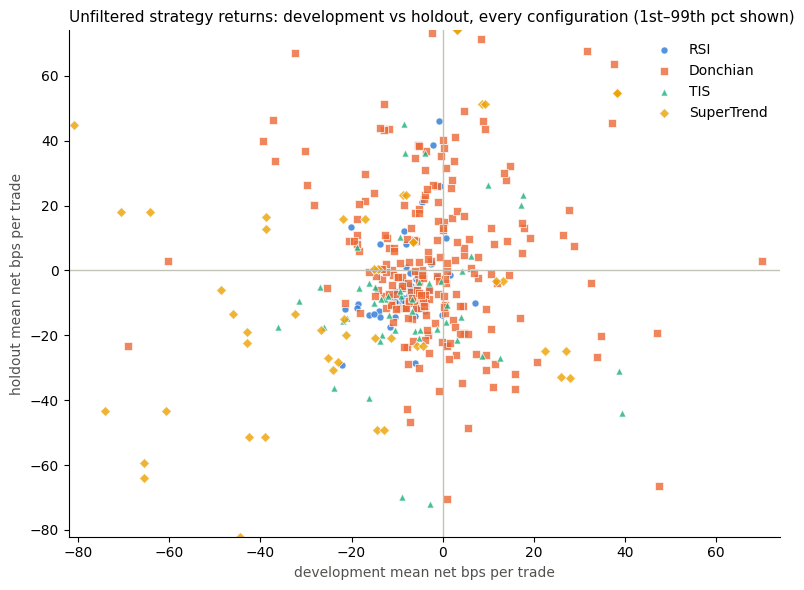

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
styles = {"RSI": dict(color="#2a78d6", marker="o"), "Donchian": dict(color="#eb6834", marker="s"),
          "TIS": dict(color="#1baf7a", marker="^"), "SuperTrend": dict(color="#eda100", marker="D")}
for fam, st in styles.items():
    g = ok[ok["family"] == fam]
    ax.scatter(g["dev_mean_bps"], g["hold_mean_bps"], s=26, alpha=0.8, label=fam, edgecolors="#fcfcfb", linewidths=0.6, **st)
ax.axhline(0, color="#c3c2b7", lw=1); ax.axvline(0, color="#c3c2b7", lw=1)
lo = np.nanpercentile(np.r_[ok["dev_mean_bps"], ok["hold_mean_bps"]], [1, 99])
ax.set_xlim(lo); ax.set_ylim(lo)
ax.set_xlabel("development mean net bps per trade", color="#52514e"); ax.set_ylabel("holdout mean net bps per trade", color="#52514e")
ax.set_title("Unfiltered strategy returns: development vs holdout, every configuration (1st–99th pct shown)", loc="left", fontsize=11)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 6. Conclusions (this execution; selection fingerprint printed in section 4)

**Short answer.** Changing the bar threshold, the asset, the strategy or its threshold parameters changes the results a lot on development data, but
**no configuration gives a positive result that survives the number of configurations tried.** The development rankings do not carry over to the
holdout.

### How the results change

* **Costs dominate the economics.** Development gross returns are positive in 74 % of Donchian, 69 % of RSI, 57 % of TIS and 33 % of SuperTrend
  configurations. After the 10 bps round trip, the net mean is positive in only 41 %, 4 %, 32 % and 27 %. Only 1.9 % of Donchian configurations have
  development t > 2, and no other family has any.
* **Bar threshold.** Coarser bars (about 25 per day) fare better net. With a fixed per-trade cost they produce fewer trades with larger moves. For
  Donchian, the median development net is +0.9 bps at 25 bars per day vs. −5.3 / −4.5 at 50 / 100, and the holdout medians are +8.4 / +7.0 / −7.4.
  Volume bars do slightly better than notional bars. This is a cost-to-move-size effect, not a fitted edge.
* **Strategy thresholds.**
  * **Donchian:** a stricter breakout (`min_break_atr = 1`) and a higher `adx_min` raise the gross return per trade (development median about +10 bps
    vs. +4 bps at 0.25), but they cut the trade count 3–10×.
  * **RSI:** loses net at every level.
  * **SuperTrend:** loses net at every score; `min_signal_score = 80` is much worse.
  * **TIS:** `streak_length = 3` is the least bad.
  * No parameter value is positive net in a majority of datasets on both development and holdout. The best is Donchian `adx_min=22, min_break_atr=0.5`
    at 52 % on both.
* **Meta-model predictability.** The median development AUC is 0.512. Only 39 of 364 modelled configurations beat the prior in log loss.
  75 configurations have nominal p(AUC > 0.5) < 0.05, against 18 expected by chance, so the AUC distribution is shifted slightly to the right.
  36 pass BH at 5 %, and 8 also beat the prior.

### Does tuning these parameters give positive results? The holdout check

* **Predictive (P).** Out of the 8 configurations that passed on development (all Donchian), **none** is predictive on the holdout: holdout AUC is
  0.42–0.53, no p-value is below 0.17, and the holdout log loss is worse than the prior in 7 of 8.
  * Across all configurations, the Spearman correlation between development and holdout AUC is **0.06**.
  * Configurations that beat the prior on development beat it on the holdout in 4 of 35 cases (11 %), vs. 64 of 304 (21 %) for the rest.
  * The development–holdout correlation of Δ log loss (0.54) reflects how much each configuration's model *overfits* (RSI and TIS overfit most),
    not signal.
* **Unfiltered economics (E1).** **No configuration has DSR > 0.95**, even with the lenient `N = 20`. The development top-5 by t-stat are all Donchian
  with `min_break_atr = 1` and few trades (30–139); 3 of 5 are positive on the holdout. The best is BTC notional 25: +111 bps on 16 trades, t = 2.1,
  which is not significant after selecting 5 of 523 (Holm). Across all configurations, the Spearman correlation between development and holdout net
  mean is **0.04**.
* **Meta-filtered economics (E2).**
  * **On development:** no configuration has DSR > 0.95. The fixed `p ≥ 0.5` filter raises the development mean in 210 of 364 configurations.
  * **On the holdout:** the filter raises the mean in 156 of 297 configurations (median +0.4 bps). Development and holdout filtered returns are
    uncorrelated (Spearman 0.01).
  * **Top-5 filtered candidates:** all SuperTrend, and they collapse on the holdout (filtered means −57 to −189 bps).

### What remains

* **One consistent, unselected pattern:** the Donchian breakout is gross-positive (median about +9 bps per trade on the holdout, positive in 71 % of
  configurations), and its net result depends on cost and bar coarseness. This is a hypothesis about **execution cost** (maker fees, fewer and larger
  trades), not about meta-labeling. It can only be confirmed on data after 2026-08-31, with the cost level, bar size and parameter fixed in advance.
* **Caveats.**
  * The 10 bps round trip is optimistic for retail taker fees (10 bps per fill).
  * The 30 datasets are 5 assets seen through 6 bar definitions, so they are not independent.
  * BTC and ETH holdout periods were partly seen in earlier notebooks.
  * One fixed meta-model (RF, full eligible features). Other learners were not tried, deliberately, to keep the number of trials down.
  * A configuration with few trades (25 bars per day, strict thresholds) has very wide intervals in both directions.
